In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MaxAbsScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv(r"C:\Users\prana\Downloads\emails.csv")

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (5172, 3002)


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [3]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Number of columns:", df.shape[1])

Missing values: 0
Duplicate rows: 0
Number of columns: 3002


In [5]:
# Remove duplicate and missing rows
df = df.drop_duplicates()
df = df.dropna()

# X = input features
X = df.drop(columns=["Prediction", "Email No."])

# y = target/output
y = df["Prediction"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts())

Features shape: (5172, 3000)
Target shape: (5172,)

Class distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64


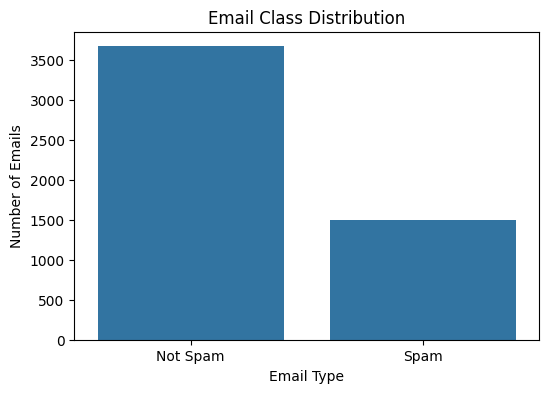

In [6]:
plt.figure(figsize=(6, 4))

sns.countplot(x=y)

plt.xticks(
    [0, 1],
    ["Not Spam", "Spam"]
)

plt.title("Email Class Distribution")
plt.xlabel("Email Type")
plt.ylabel("Number of Emails")

plt.show()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4137, 3000)
Testing data: (1035, 3000)


In [8]:
scaler = MaxAbsScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed.")

Scaling completed.


In [9]:
knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(X_train_scaled, y_train)

knn_pred = knn.predict(X_test_scaled)

print("KNN classification completed.")

KNN classification completed.


In [10]:
svm = LinearSVC(
    C=1.0,
    max_iter=500,
    random_state=42
)

svm.fit(X_train_scaled, y_train)

svm_pred = svm.predict(X_test_scaled)

print("SVM classification completed.")

SVM classification completed.


In [11]:
knn_accuracy = accuracy_score(y_test, knn_pred)

print("KNN Accuracy:", knn_accuracy)

KNN Accuracy: 0.8763285024154589


In [12]:
knn_precision = precision_score(y_test, knn_pred)

print("KNN Precision:", knn_precision)

KNN Precision: 0.7239583333333334


In [13]:
knn_recall = recall_score(y_test, knn_pred)

print("KNN Recall:", knn_recall)

KNN Recall: 0.9266666666666666


In [14]:
knn_f1 = f1_score(y_test, knn_pred)

print("KNN F1 Score:", knn_f1)

KNN F1 Score: 0.8128654970760235


In [15]:
svm_accuracy = accuracy_score(y_test, svm_pred)

print("SVM Accuracy:", svm_accuracy)

SVM Accuracy: 0.9710144927536232


In [16]:
svm_precision = precision_score(y_test, svm_pred)

print("SVM Precision:", svm_precision)

SVM Precision: 0.9299363057324841


In [17]:
svm_recall = recall_score(y_test, svm_pred)

print("SVM Recall:", svm_recall)

SVM Recall: 0.9733333333333334


In [18]:
svm_f1 = f1_score(y_test, svm_pred)

print("SVM F1 Score:", svm_f1)

SVM F1 Score: 0.9511400651465798


In [19]:
results = pd.DataFrame({
    "Model": ["KNN", "SVM"],
    
    "Accuracy": [
        knn_accuracy,
        svm_accuracy
    ],
    
    "Precision": [
        knn_precision,
        svm_precision
    ],
    
    "Recall": [
        knn_recall,
        svm_recall
    ],
    
    "F1 Score": [
        knn_f1,
        svm_f1
    ]
})

results = results.round(4)

display(results)

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.8763,0.7240,0.9267,0.8129
1,SVM,0.9710,0.9299,0.9733,0.9511


In [20]:
print("KNN Classification Report")

print(
    classification_report(
        y_test,
        knn_pred,
        target_names=["Not Spam", "Spam"]
    )
)

KNN Classification Report
              precision    recall  f1-score   support

    Not Spam       0.97      0.86      0.91       735
        Spam       0.72      0.93      0.81       300

    accuracy                           0.88      1035
   macro avg       0.85      0.89      0.86      1035
weighted avg       0.90      0.88      0.88      1035

